# Лабораторная работа №2: Кластерный анализ методом k-средних (k-means)
**Студент:** Любецкая Антонина  
**Цель исследования:** Провести кластеризацию 48 городов мира методом k-средних (k-means) на основе экономических показателей (часы работы, индекс цен, индекс зарплат), определить оптимальное число кластеров, выделить типичных представителей (центроиды) и сопоставить результаты с иерархической кластеризацией.  
**Гипотеза:** Алгоритм k-means подтвердит разделение городов на 3 экономические зоны, аналогичные результатам иерархического анализа, при этом позволит точно определить города-эталоны для каждого кластера.

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, pairwise_distances_argmin_min
from sklearn.decomposition import PCA

In [47]:
plt.style.use('ggplot')
%matplotlib inline

# Шаг 1: Загрузка, предобработка данных и проверка гипотезы о пропусках
Как и в первой работе, в исходном датасете есть заглушки `-9999` и строковые числа с запятыми. Переводим их в `NaN` и числовой тип `float`.

In [ ]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=';', index_col='City')

In [49]:
# Очистка и приведение типов
df_clean = df_raw.replace([-9999, '-9999'], np.nan)
df_clean['Price'] = pd.to_numeric(df_clean['Price'].astype(str).str.replace(',', '.'), errors='coerce')
df_clean['Salary'] = pd.to_numeric(df_clean['Salary'].astype(str).str.replace(',', '.'), errors='coerce')

In [ ]:
# Смотрим сколько всего строк с пропусками
print("Города с пропусками в данных:")
print(df_clean[df_clean.isna().any(axis=1)])

Города с пропусками в данных:
         Work  Price  Salary
City                        
Cairo     NaN   37.1     NaN
Jakarta   NaN   43.6     NaN


In [51]:
# Основной вариант: заполняем пропуски медианой
df = df_clean.fillna(df_clean.median(numeric_only=True))

In [ ]:
# Альтернативный вариант: удаляем строки с пропусками
df_dropped = df_clean.dropna()

**Масштабирование и выбор метрики расстояния:**  
Алгоритм k-means минимизирует внутрикластерную дисперсию (Inertia - сумму квадратов расстояний от точек до центроидов своих кластеров). Математически минимизация суммы квадратов жестко привязана к **евклидову расстоянию**, поэтому в классическом k-means используется именно оно.  
Так как евклидово расстояние чувствительно к масштабу, а `Work` измеряется в тысячах часов (1500–2400), в то время как `Price` и `Salary` - в процентах относительно Цюриха (10–130), применяем `StandardScaler` (среднее = 0, стандартное отклонение = 1).

In [54]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
df_scaled = pd.DataFrame(X_scaled, columns=df.columns, index=df.index)
df_scaled.head()

,Work,Price,Salary
City,,,
Amsterdam,-0.974577,-0.151250,0.387038
Athens,-0.512818,-0.698647,-0.388428
Bogota,1.618375,-1.436242,-1.176402
Bombay,1.026377,-1.788804,-1.434891
Brussels,-1.010097,0.229145,0.449576


# Шаг 2: Определение оптимального числа кластеров
Чтобы выбрать число кластеров $k$, используем сразу два подхода:
1. **Метод локтя:** смотрим на падение `Inertia` (суммы квадратов внутрикластерных расстояний). Ищем точку перегиба, после которой ошибка начинает падать медленно.
2. **Коэффициент силуэта:** показывает, насколько объекты внутри кластера похожи друг на друга по сравнению с объектами из ближайшего соседнего кластера. Принимает значения от -1 до 1 (чем ближе к 1, тем четче разделение).

В `KMeans` фиксируем `random_state=42` для воспроизводимости (так как начальные центроиды выбираются со случайной инициализацией `k-means++`) и задаем `n_init=10` (алгоритм запустится 10 раз с разными стартовыми центрами и выберет лучший вариант по Inertia).

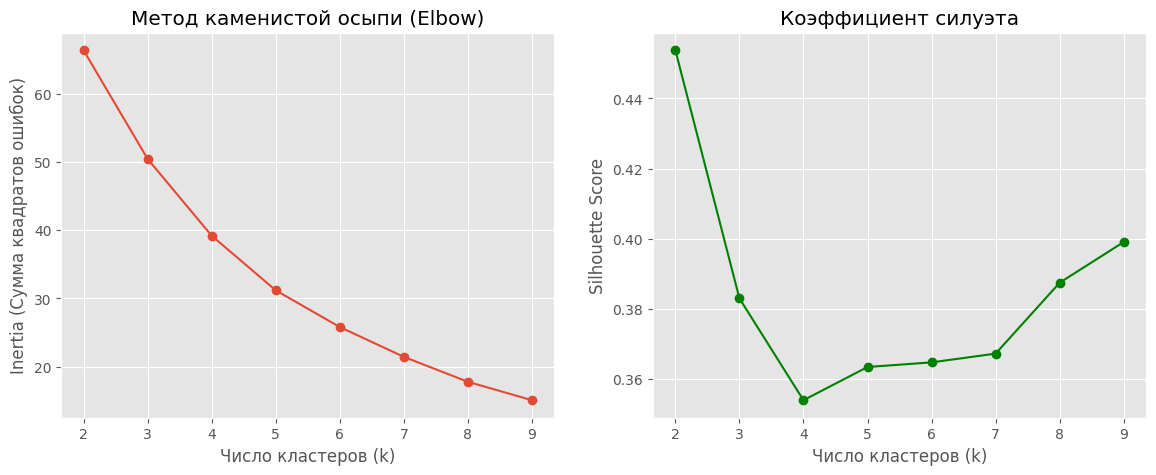

In [55]:
inertia = []
silhouette = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График локтя
ax1.plot(K_range, inertia, marker='o')
ax1.set_title('Метод каменистой осыпи (Elbow)')
ax1.set_xlabel('Число кластеров (k)')
ax1.set_ylabel('Inertia (Сумма квадратов ошибок)')
ax1.grid(True)

# График силуэта
ax2.plot(K_range, silhouette, marker='o', color='green')
ax2.set_title('Коэффициент силуэта')
ax2.set_xlabel('Число кластеров (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.show()

**Анализ графиков и выбор между $k=2$ и $k=3$:**  
По графику силуэта формальный максимум достигается при $k=2$ ($0.45$), а при $k=3$ значение опускается до $0.382$. При этом на графике метода локтя при переходе от $k=2$ к $k=3$ наблюдается сильное снижение ошибки, а сам плавный излом находится в районе $k=3$–$4$.

Проверим содержательно (по средним значениям признаков), что именно происходит с городами при $k=2$, $k=3$ и $k=4$, чтобы не опираться вслепую только на одну метрику.

In [56]:
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters = km.fit_predict(X_scaled)
    
    temp_df = df.copy()
    temp_df['Cluster'] = clusters
    
    print(f"Разбиение на {k} кластера (Silhouette: {silhouette_score(X_scaled, clusters):.3f}, Inertia: {km.inertia_:.1f}) ")
    summary = temp_df.groupby('Cluster')[['Work', 'Price', 'Salary']].mean().round(1)
    summary['Count'] = temp_df['Cluster'].value_counts()
    print(summary)
    print("\n")

Разбиение на 2 кластера (Silhouette: 0.454, Inertia: 66.4) 
           Work  Price  Salary  Count
Cluster                              
0        1789.2   85.0    59.0     25
1        1975.8   51.3    18.7     23


Разбиение на 3 кластера (Silhouette: 0.383, Inertia: 50.5) 
           Work  Price  Salary  Count
Cluster                              
0        1854.5   49.2    20.8     13
1        1789.2   85.0    59.0     25
2        2133.5   54.2    16.1     10


Разбиение на 4 кластера (Silhouette: 0.354, Inertia: 39.2) 
           Work  Price  Salary  Count
Cluster                              
0        1792.0   77.5    55.2     19
1        2092.9   53.3    14.2     13
2        1823.5   48.8    24.6     10
3        1780.5  108.6    71.3      6




**Обоснование выбора $k=3$:**  
Из таблиц выше видно ключевую особенность наших данных:

* **Почему не $k=2$:** Мир делится слишком грубо - на 25 богатых городов (`Work: 1789.2`, `Price: 85.0`, `Salary: 59.0`) и 23 развивающихся (`Work: 1975.8`, `Price: 51.3`, `Salary: 18.7`). Силуэт здесь формально выше ($0.454$) только из-за того, что геометрически все небогатые города лежат далеко от богатых. Но при таком слиянии мы теряем экономическое различие по условиям труда внутри развивающихся стран.
* **Что дает $k=3$:** Кластер из 25 развитых городов остается абсолютно неизменным. А вот группа из 23 более бедных городов четко распадается на две принципиально разные подгруппы: 13 городов с нормальным графиком работы (`1854.5` ч) и 10 индустриальных центров с экстремальными переработками (`2133.5` ч в год - разница почти 280 часов!) и самыми низкими зарплатами (`16.1`). 
* **Почему не $k=4$:** Начинается искусственное дробление. Единый кластер развитых стран разбивается на 19 обычных развитых городов и 6 супер-дорогих мегаполисов (индекс цен подскочил до `108.6`). При этом рабочие часы у них практически идентичны (`1792.0` и `1780.5`). Мы не получаем принципиально новой модели рынка труда, а алгоритм просто изолирует немногочисленную элиту. Коэффициент силуэта при этом падает до минимума ($0.354$).

**Итог:** Выбираем **$k=3$** - это дает оптимальный баланс между качеством метрики (устойчивый силуэт $0.383$, существенное падение ошибки Inertia с 66.4 до 50.5) и глубокой содержательной интерпретацией, полностью согласуясь с результатами иерархического анализа.

**Дополнительная проверка: что было бы, если удалить пропуски (`dropna`) вместо замены медианой?**

In [57]:
X_dropped_scaled = StandardScaler().fit_transform(df_dropped)
km_dropped = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_dropped = km_dropped.fit_predict(X_dropped_scaled)

temp_dropped = df_dropped.copy()
temp_dropped['Cluster'] = labels_dropped
summary_dropped = temp_dropped.groupby('Cluster')[['Work', 'Price', 'Salary']].mean().round(1)
summary_dropped['Count'] = temp_dropped['Cluster'].value_counts()
print(summary_dropped)

           Work  Price  Salary  Count
Cluster                              
0        1855.5   50.8    16.6     11
1        1789.2   85.0    59.0     25
2        2133.5   54.2    16.1     10


# Шаг 3: Обучение модели k-means ($k=3$) и визуализация (3D и 2D)

In [58]:
# Обучаем модель на 3 кластерах
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

In [ ]:
df['Cluster'] = df['Cluster'] + 1

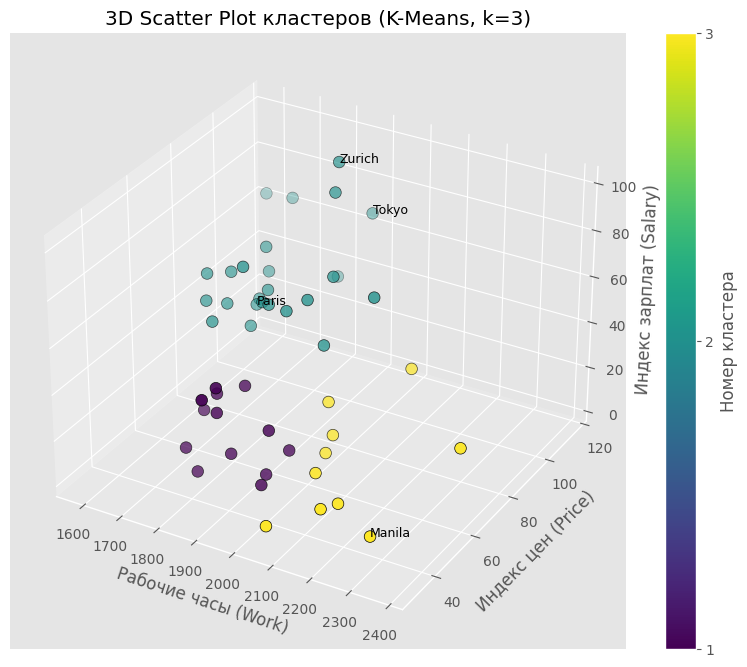

In [60]:
# 3D Scatter Plot в исходных признаках
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df['Work'], df['Price'], df['Salary'], 
                     c=df['Cluster'], cmap='viridis', s=70, edgecolor='k')

for city in ['Zurich', 'Tokyo', 'Moscow', 'HongKong', 'Manila', 'Paris']:
    if city in df.index:
        ax.text(df.loc[city, 'Work'], df.loc[city, 'Price'], df.loc[city, 'Salary'], city, fontsize=9)

ax.set_title('3D Scatter Plot кластеров (K-Means, k=3)')
ax.set_xlabel('Рабочие часы (Work)')
ax.set_ylabel('Индекс цен (Price)')
ax.set_zlabel('Индекс зарплат (Salary)')
plt.colorbar(scatter, label='Номер кластера', ticks=[1, 2, 3])
plt.show()

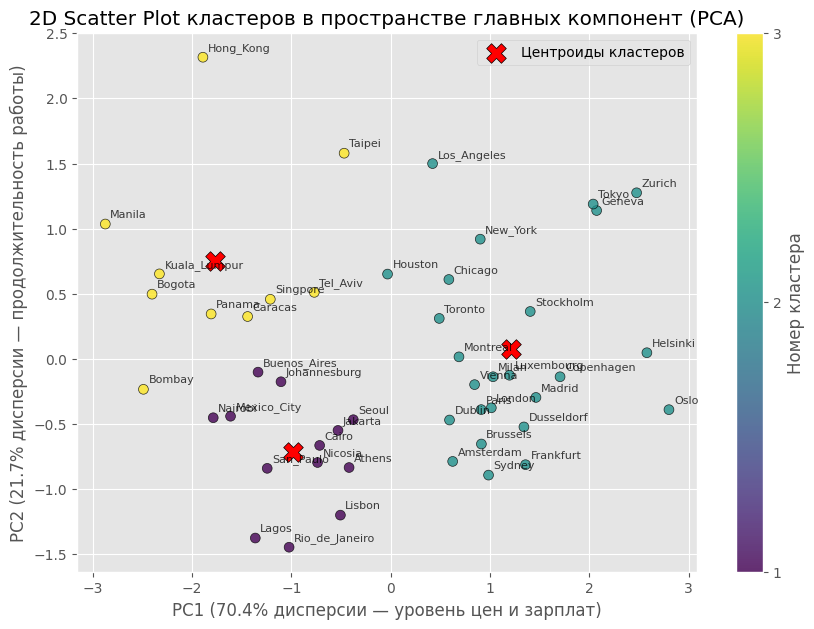

In [66]:
# 2D визуализация с помощью PCA + центроиды
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['Cluster'], cmap='viridis', s=50, edgecolor='k', alpha=0.8)

# Отрисовка центроидов
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='red', marker='X', s=200, edgecolor='black', label='Центроиды кластеров')

# Подпишем города на 2D проекции
for i, city in enumerate(df.index):
    plt.annotate(city, (X_pca[i, 0] + 0.05, X_pca[i, 1] + 0.05), fontsize=8, alpha=0.75)

plt.title('2D Scatter Plot кластеров в пространстве главных компонент (PCA)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии — уровень цен и зарплат)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии — продолжительность работы)')
plt.legend()
plt.colorbar(scatter, label='Номер кластера', ticks=[1, 2, 3])
plt.grid(True)
plt.show()

# Шаг 4: Экономическое профилирование
Важное преимущество метода k-means - наличие явных центроидов (`cluster_centers_`). Мы можем найти реальный город из датасета, который находится на минимальном евклидовом расстоянии от математического центра своего кластера. Такой город является «эталонным представителем» своей экономической группы.

In [62]:
# Средние показатели по кластерам
cluster_summary = df.groupby('Cluster')[['Work', 'Price', 'Salary']].mean().round(1)
cluster_summary['Count'] = df['Cluster'].value_counts()
print("Средние значения показателей по кластерам:")
print(cluster_summary)

Средние значения показателей по кластерам:
           Work  Price  Salary  Count
Cluster                              
1        1854.5   49.2    20.8     13
2        1789.2   85.0    59.0     25
3        2133.5   54.2    16.1     10


In [67]:
# Поиск ближайшего города к каждому центроиду
closest_indices, distances = pairwise_distances_argmin_min(kmeans_final.cluster_centers_, X_scaled)

print("Типичные представители (города, ближайшие к центроидам):")
for cluster_idx, city_idx in enumerate(closest_indices):
    city_name = df.index[city_idx]
    cluster_num = cluster_idx + 1
    print(f"Кластер {cluster_num}: эталонный город - {city_name} (расстояние до центра: {distances[cluster_idx]:.3f})")
    print(f"   Показатели {city_name}: {df.loc[city_name, ['Work', 'Price', 'Salary']].to_dict()}")

Типичные представители (города, ближайшие к центроидам):
Кластер 1: эталонный город - Nicosia (расстояние до центра: 0.365)
   Показатели Nicosia: {'Work': 1825.0, 'Price': 47.9, 'Salary': 28.3}
Кластер 2: эталонный город - Milan (расстояние до центра: 0.292)
   Показатели Milan: {'Work': 1773.0, 'Price': 82.0, 'Salary': 53.3}
Кластер 3: эталонный город - Panama (расстояние до центра: 0.412)
   Показатели Panama: {'Work': 2078.0, 'Price': 49.2, 'Salary': 13.8}


In [64]:
# Полный состав каждого кластера
for c in sorted(df['Cluster'].unique()):
    cities = df[df['Cluster'] == c].index.tolist()
    print(f"\nКластер {c} ({len(cities)} городов):")
    print(", ".join(cities))


Кластер 1 (13 городов):
Athens, Buenos_Aires, Cairo, Jakarta, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul

Кластер 2 (25 городов):
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Кластер 3 (10 городов):
Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv


## Выводы по работе
В ходе кластерного анализа методом k-средних (k-means) 48 городов мира были разделены на **3 кластера**. Благодаря вычислению расстояний до математических центров групп (центроидов) удалось не только профилировать группы, но и выделить эталонные города для каждой экономической модели.

1. **Кластер 1 — Развивающиеся рынки с умеренной трудовой нагрузкой (13 городов):**  
   * *Средние показатели:* `Work = 1854.5` ч, `Price = 49.2`, `Salary = 20.8`.  
   * *Эталонный представитель:* **Nicosia** (расстояние до центра: 0.365).
   * *Состав:* Athens, Buenos Aires, Cairo, Jakarta, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul.
   * *Интерпретация:* Города с самыми низкими ценами на жизнь и невысокими зарплатами, но при этом с нормальной, не завышенной продолжительностью рабочего года (на уровне европейских стандартов).  

2. **Кластер 2 — Экономически развитые мегаполисы с высоким уровнем жизни (25 городов):**  
   * *Средние показатели:* `Work = 1789.2` ч, `Price = 85.0`, `Salary = 59.0`.  
   * *Эталонный представитель:* **Milan** (расстояние до центра: 0.292).
   * *Состав:* Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich.
   * *Интерпретация:* Богатые города Западной Европы, Северной Америки и развитой Азии. Здесь самые высокие зарплаты и высокая стоимость жизни, но люди работают меньше всего часов в год благодаря высокой производительности труда и сильной социальной защите.  

3. **Кластер 3 — Индустриальные центры с интенсивным трудом и переработками (10 городов):**  
   * *Средние показатели:* `Work = 2133.5` ч, `Price = 54.2`, `Salary = 16.1`.  
   * *Эталонный представитель:* **Panama** (расстояние до центра: 0.412).
   * *Состав:* Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv.
   * *Интерпретация:* Города с самым тяжелым режимом труда (более 2100 рабочих часов в год) и самыми низкими зарплатами, при том что цены здесь даже немного выше, чем в первом кластере.

**Итог и сравнение с иерархической кластеризацией:**  
Выбор 3 кластеров обоснован комбинацией метода локтя, коэффициента силуэта ($0.383$) и глубокой содержательной интерпретируемостью (при $k=2$ теряется критическое различие по рабочим часам между развивающимися городами). Экспериментально подтверждено, что заполнение пропусков медианой не смещает центры кластеров по сравнению с удалением строк (`dropna`), позволяя сохранить все 48 городов. Результаты k-means полностью подтверждают структуру, выявленную в Лабораторной работе №1, а выделенные города-эталоны (Никосия, Милан, Панама) делают экономический профиль каждой группы максимально наглядным.